# Пригодность данных Ankerprognose для прогнозирования

Временная ось — **erstes Ladedatum**. Единица анализа — уникальный случай
`BWPKKD + Ankerbeginn` в когорте `Ankerjahr × Sachverhalt`.
Исследуем приросты и накопленные Fälle и Lückentage на регулярной недельной сетке.

Notebook читает локальную DuckDB без изменений. Прогнозы и записи в forecast_runs не создаются.
Выходные таблицы агрегированы и не содержат идентификаторов случаев.
Для запуска выберите Python-окружение проекта с pandas, numpy, duckdb и matplotlib/seaborn,
а также установленным ipykernel для Jupyter/VS Code. Выполните Run All.


In [1]:
from pathlib import Path
import sys
import hashlib
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', palette='deep')

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "pack" / "data_access.py").exists()),
    None,
)
if ROOT is None:
    raise RuntimeError("Откройте notebook из папки проекта или notebooks.")
sys.path.insert(0, str(ROOT))
from pack.config import DB_PATH

# Параметры исследования. None выбирает последний доступный год.
ANCHOR_YEAR = None
SACHVERHALT = "all"
HORIZON_WEEKS = 13
MIN_TRAIN_WEEKS = 52
# True допустимо только после подтверждения полноты выгрузки.
CONFIRMED_COMPLETE_EXTRACT = False
# Подтвержденная дата полноты данных по erstes Ladedatum, например "2026-11-09".
# Максимальная дата записи сама по себе полноту выгрузки не доказывает.
OBSERVATION_END = None
SHOW_PLOTS = True

def show(fig):
    if SHOW_PLOTS:
        fig.tight_layout()
        plt.show()
    plt.close(fig)

database = Path(DB_PATH)
if not database.is_file():
    raise FileNotFoundError(f"Локальная база отсутствует: {database}")
database_hash_before = hashlib.sha256(database.read_bytes()).hexdigest()
con = duckdb.connect(str(database), read_only=True)
try:
    raw = con.execute('''
        SELECT
            CAST("/B99/S_BWPKKD" AS VARCHAR) AS case_id,
            CAST("/BIC/YBWRSV" AS VARCHAR) AS sachverhalt,
            CAST("/BIC/YBWRSEL" AS VARCHAR) AS selection,
            CAST("/BIC/YBWRIQIQ" AS VARCHAR) AS iq,
            CAST("/BIC/YBWRAVON" AS VARCHAR) AS anchor_start_raw,
            CAST("/BIC/YBWRABIS" AS VARCHAR) AS anchor_end_raw,
            CAST("/BIC/YBWRELAD" AS VARCHAR) AS load_raw,
            CAST("/BIC/YBWRIPL" AS VARCHAR) AS ipl_raw,
            TRY_CAST("/BIC/YBWRFTAGE" AS DOUBLE) AS days
        FROM raw_bestand
    ''').df()
finally:
    con.close()

if raw.empty:
    raise RuntimeError(
        "raw_bestand пуста. Сначала загрузите данные через приложение."
    )

display(pd.Series({
    "Строк": len(raw),
    "Размер базы, MiB": round(database.stat().st_size / 1024**2, 2),
    "Время исследования": str(pd.Timestamp.now()),
}, name="Источник").to_frame())

,Источник
Строк,548873
"Размер базы, MiB",10.51
Время исследования,2026-11-20 09:43:53.544648


## 1. Полнота и качество

Отбираем RSA / 4.15.1, как в импорте приложения. Неподходящие строки учитываются
в отчёте. Даты YYYYMMDD, YYYY-MM-DD и DD.MM.YYYY разбираются явно.
IPL используется для выбора последнего состояния случая и проверки снимков.
Ось временных рядов строится по erstes Ladedatum.


In [2]:
def parse_dates(values):
    text = values.astype("string").str.strip()
    dotted = text.str.fullmatch(r"\d{2}\.\d{2}\.\d{4}", na=False)
    parsed = pd.to_datetime(text.where(~dotted), format="mixed", errors="coerce")
    parsed.loc[dotted] = pd.to_datetime(
        text.loc[dotted], format="%d.%m.%Y", errors="coerce"
    )
    return parsed

scope = raw["selection"].eq("4.15.1") & raw["iq"].eq("RSA")
display(pd.Series({"Все строки": len(raw), "RSA / 4.15.1": int(scope.sum()),
                   "Вне выборки": int((~scope).sum())}).to_frame("Строк"))
data = raw.loc[scope].copy()
if data.empty:
    raise RuntimeError("Нет записей RSA / 4.15.1.")
for target, source in [
    ("anchor_start", "anchor_start_raw"), ("anchor_end", "anchor_end_raw"),
    ("load_date", "load_raw"), ("ipl_date", "ipl_raw"),
]:
    data[target] = parse_dates(data[source])
checks = {
    "Пустой case_id": data["case_id"].fillna("").str.strip().eq(""),
    "Некорректный Ankerbeginn": data["anchor_start"].isna(),
    "Некорректный Ankerende": data["anchor_end"].isna(),
    "Некорректный erstes Ladedatum": data["load_date"].isna(),
    "Некорректный IPL": data["ipl_date"].isna(),
    "Некорректные Lückentage": data["days"].isna() | ~np.isfinite(data["days"]),
    "Отрицательные Lückentage": data["days"].lt(0),
    "Дробные Lückentage": data["days"].notna() & data["days"].mod(1).ne(0),
    "Ankerende раньше Ankerbeginn": data["anchor_end"].lt(data["anchor_start"]),
    "Первая загрузка раньше Ankerbeginn": data["load_date"].lt(data["anchor_start"]),
    "IPL раньше первой загрузки": data["ipl_date"].lt(data["load_date"]),
}
quality = pd.DataFrame({
    "Проверка": list(checks),
    "Строк": [int(mask.sum()) for mask in checks.values()],
})
display(quality)
display(data.groupby("sachverhalt", dropna=False).agg(
    rows=("case_id", "size"), first_load=("load_date", "min"),
    last_load=("load_date", "max"), last_ipl=("ipl_date", "max"),
).reset_index())
key = ["case_id", "anchor_start"]
valid = data.dropna(subset=["anchor_start", "anchor_end", "load_date", "ipl_date", "days"])
valid = valid.loc[valid["case_id"].fillna("").str.strip().ne("")].copy()
consistency = valid.groupby(key).agg(
    snapshots=("case_id", "size"),
    load_dates=("load_date", "nunique"),
    anchor_ends=("anchor_end", "nunique"),
    categories=("sachverhalt", "nunique"),
    day_values=("days", "nunique"),
)
display(pd.Series({
    "Уникальных ключей": len(consistency),
    "Ключей в нескольких строках": int(consistency["snapshots"].gt(1).sum()),
    "Разные даты первой загрузки": int(consistency["load_dates"].gt(1).sum()),
    "Разные даты окончания": int(consistency["anchor_ends"].gt(1).sum()),
    "Разные Sachverhalt": int(consistency["categories"].gt(1).sum()),
    "Изменялись Lückentage": int(consistency["day_values"].gt(1).sum()),
    "Повтор ключа в одном IPL": int(valid.duplicated(key + ["ipl_date"]).sum()),
}).to_frame("Количество"))


,Строк
Все строки,548873
RSA / 4.15.1,548873
Вне выборки,0


,Проверка,Строк
0,Пустой case_id,0
1,Некорректный Ankerbeginn,0
2,Некорректный Ankerende,250400
3,Некорректный erstes Ladedatum,0
4,Некорректный IPL,0
5,Некорректные Lückentage,0
6,Отрицательные Lückentage,0
7,Дробные Lückentage,0
8,Ankerende раньше Ankerbeginn,73
9,Первая загрузка раньше Ankerbeginn,0


,sachverhalt,rows,first_load,last_load,last_ipl
0,000,20717,2015-09-04,2026-11-14,2026-11-14
1,004,205742,2015-07-03,2026-02-07,2026-02-14
2,005,1801,2020-05-30,2026-11-14,2026-11-14
3,01a,70347,2015-07-03,2026-11-14,2026-11-14
4,01b,127645,2015-07-03,2026-11-14,2026-11-14
5,01c,87263,2019-02-24,2026-11-14,2026-11-14
6,02b,9682,2017-07-17,2023-07-16,2023-07-24
7,02c,5102,2019-04-28,2023-07-16,2023-07-24
8,03b,6242,2016-11-25,2023-07-16,2023-07-24
9,03c,5551,2019-05-04,2023-07-16,2023-07-24


,Количество
Уникальных ключей,273218
Ключей в нескольких строках,24254
Разные даты первой загрузки,7318
Разные даты окончания,1143
Разные Sachverhalt,11115
Изменялись Lückentage,1619
Повтор ключа в одном IPL,19234


### Проверка нераспознанных дат Ankerende

Показываем исходные значения до преобразования, чтобы отличить открытые периоды (например, 9999-12-31) от пустых или ошибочных дат. Примеры и частоты берутся из всей выборки RSA / 4.15.1 до исключения строк.


In [ ]:
invalid_end = data.loc[data["anchor_end"].isna()]
print(f"Нераспознанных дат Ankerende: {len(invalid_end):,}")
display(
    invalid_end[
        ["anchor_start_raw", "anchor_end_raw", "load_raw", "ipl_raw"]
    ].head(10)
)
display(
    invalid_end["anchor_end_raw"]
    .value_counts(dropna=False)
    .head(10)
    .to_frame("Количество")
)


### Ankerende раньше Ankerbeginn

Отдельная проверка распознанных дат: количество строк и первые 10 примеров, в которых окончание анкерного периода раньше его начала. Исходные значения показаны для проверки источника.


In [ ]:
reversed_periods = data.loc[
    data["anchor_start"].notna()
    & data["anchor_end"].notna()
    & data["anchor_end"].lt(data["anchor_start"])
]

print(f"Строк, где Ankerende раньше Ankerbeginn: {len(reversed_periods):,}")
display(
    reversed_periods[
        ["sachverhalt", "anchor_start_raw", "anchor_end_raw", "load_raw", "ipl_raw", "days"]
    ].head(10)
)


## 2. Когорта приложения и распределение значений

Отбор выполняется **до** дедупликации: период случая пересекает анкерный год,
затем применяется Sachverhalt. Для недельного ряда вызывается существующая функция
приложения. Отдельная детализация нужна для распределений.

При неоднозначном ключе с разными датами первой загрузки или несколькими значениями
в одном последнем IPL результат выбора может быть неоднозначен. Это требует проверки
источника. Notebook показывает такие случаи агрегированно.


,Выборка
Ankerjahr,2026
Sachverhalt,all
Строк снимков,19118
Уникальных случаев,17129
Первое Ladedatum,2019-02-24 00:00:00
Последнее Ladedatum,2026-11-14 00:00:00


,Lückentage / Fall
count,17129.000000
mean,61.283379
std,88.963452
min,1.000000
1%,1.000000
25%,15.000000
50%,30.000000
75%,64.000000
95%,243.000000
99%,456.720000


,Сверка
Fälle из функции приложения,253473.0
Fälle из детализации,17129.0
Lückentage из функции приложения,61320612.0
Lückentage из детализации,1049723.0


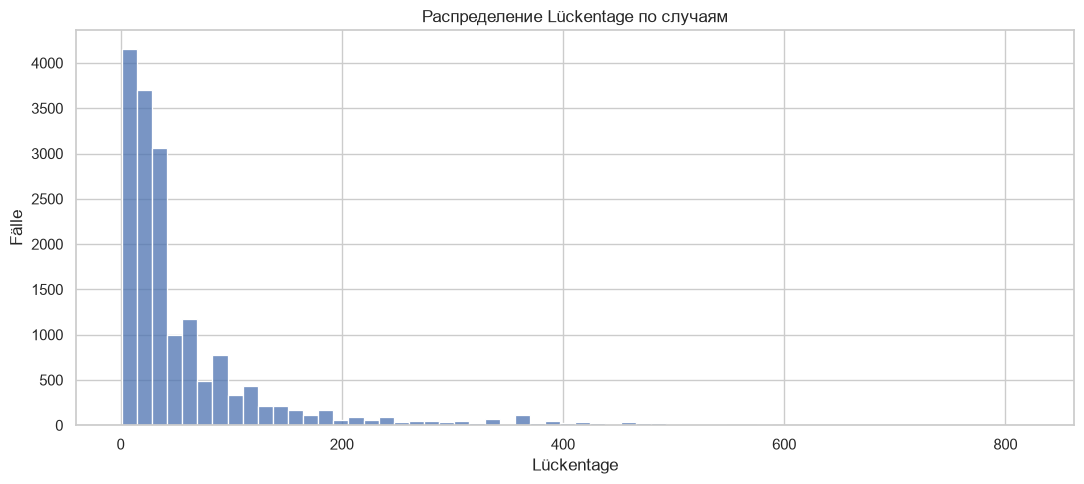

In [3]:
from pack.data_access import load_anchor_cohort_weekly_data

years = sorted(valid["anchor_start"].dt.year.unique().astype(int))
if not years:
    raise RuntimeError("Нет строк с пригодными датами.")
selected_year = int(ANCHOR_YEAR) if ANCHOR_YEAR is not None else max(years)
selected_category = str(SACHVERHALT)

selected = valid.loc[
    valid["anchor_start"].le(pd.Timestamp(selected_year, 12, 31))
    & valid["anchor_end"].ge(pd.Timestamp(selected_year, 1, 1))
].copy()
if selected_category != "all":
    selected = selected.loc[selected["sachverhalt"].eq(selected_category)]
cases = selected.sort_values("ipl_date", kind="stable").drop_duplicates(key, keep="last")
display(pd.Series({
    "Ankerjahr": selected_year, "Sachverhalt": selected_category,
    "Строк снимков": len(selected), "Уникальных случаев": len(cases),
    "Первое Ladedatum": cases["load_date"].min(),
    "Последнее Ladedatum": cases["load_date"].max(),
}).to_frame("Выборка"))
if cases.empty:
    raise RuntimeError("Когорта пуста. Измените ANCHOR_YEAR / SACHVERHALT.")
display(cases["days"].describe(percentiles=[.01, .25, .5, .75, .95, .99]).to_frame("Lückentage / Fall"))
weekly_source = load_anchor_cohort_weekly_data(selected_category, selected_year)
if weekly_source.empty:
    raise RuntimeError("Функция приложения вернула пустую когорту.")
display(pd.Series({
    "Fälle из функции приложения": int(weekly_source["FAELLE"].sum()),
    "Fälle из детализации": len(cases),
    "Lückentage из функции приложения": weekly_source["TAGEN"].sum(),
    "Lückentage из детализации": cases["days"].sum(),
}).to_frame("Сверка"))

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(data=cases, x="days", bins=60, ax=ax)
ax.set(title="Распределение Lückentage по случаям", xlabel="Lückentage", ylabel="Fälle")
show(fig)


## 3. Регулярная недельная сетка

Шаг — календарная неделя, понедельник–воскресенье. Индекс начинается с первой
недели появления данных когорты. Конец наблюдения по умолчанию — максимальное
erstes Ladedatum всей исследуемой выборки RSA / 4.15.1. Он является ориентиром,
пока полнота выгрузки не подтверждена.

Для отсутствующих недель показываются две версии:
* observed_* сохраняет NaN;
* new_* содержит сценарный нулевой прирост.

Нули допустимы при подтвержденном отсутствии новых случаев. Оранжевые точки
обозначают недели без записей, красная — последнюю неделю с неполным покрытием
до выбранной даты конца наблюдения. Отсутствие семи дат загрузки внутри недели
само по себе не делает неделю неполной.


,observed_cases,observed_days,missing_week,new_cases,new_days,cumulative_cases,cumulative_days,complete_calendar_week
week,,,,,,,,
2026-07-27,2036.0,222900.0,False,2036.0,222900.0,239729.0,59878465.0,True
2026-08-03,562.0,66523.0,False,562.0,66523.0,240291.0,59944988.0,True
2026-08-10,706.0,74452.0,False,706.0,74452.0,240997.0,60019440.0,True
2026-08-17,611.0,71733.0,False,611.0,71733.0,241608.0,60091173.0,True
2026-08-24,653.0,79181.0,False,653.0,79181.0,242261.0,60170354.0,True
2026-08-31,1718.0,187638.0,False,1718.0,187638.0,243979.0,60357992.0,True
2026-09-07,581.0,70144.0,False,581.0,70144.0,244560.0,60428136.0,True
2026-09-14,646.0,69969.0,False,646.0,69969.0,245206.0,60498105.0,True
2026-09-21,579.0,72066.0,False,579.0,72066.0,245785.0,60570171.0,True


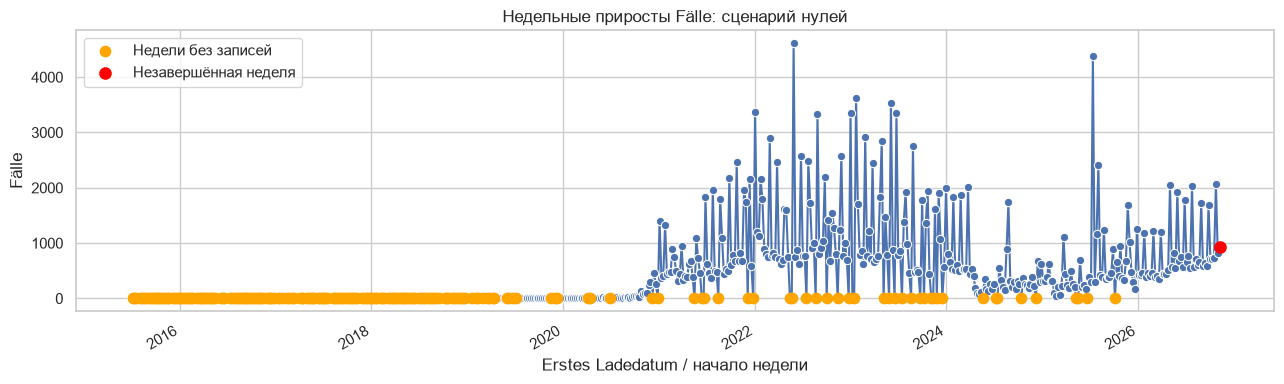

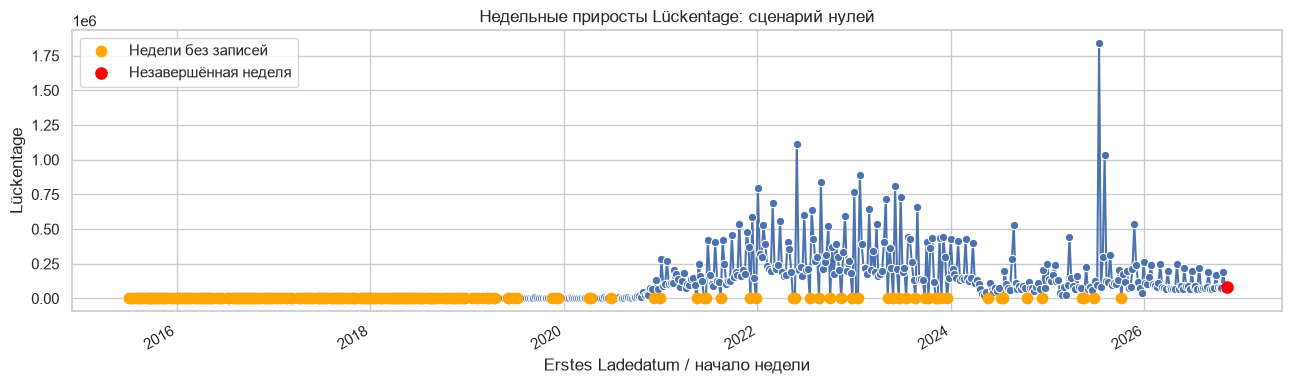

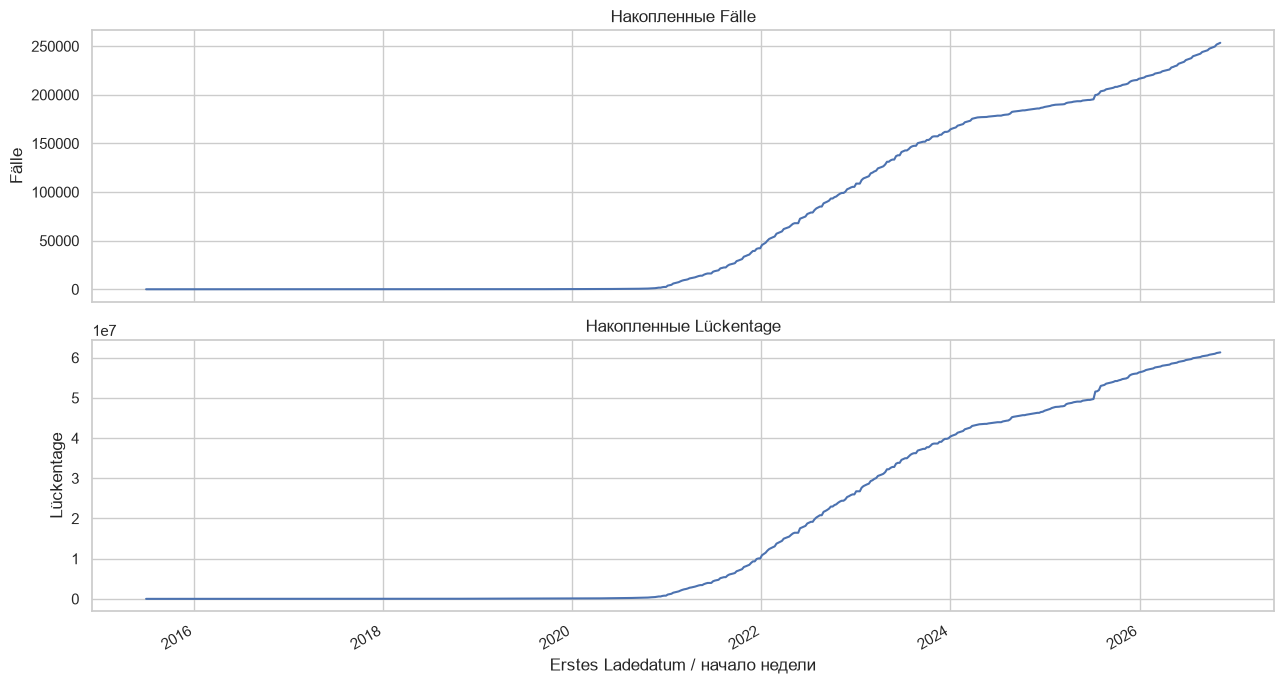

In [4]:
if "weekly_source" not in globals():
    raise RuntimeError(
        "Сначала выполните ячейку раздела 2 «Когорта приложения и распределение значений» "
        "или выберите Restart Kernel → Run All. "
        "Если предыдущая ячейка завершилась ошибкой, устраните её и выполните заново."
    )

global_end = data["load_date"].max()
observation_end = pd.Timestamp(OBSERVATION_END) if OBSERVATION_END else global_end
if observation_end < pd.Timestamp(weekly_source["IPL_dt"].max()):
    raise ValueError("OBSERVATION_END раньше последней недели когорты.")
if observation_end < selected["load_date"].max():
    raise ValueError("OBSERVATION_END раньше последней фактической даты когорты.")

def regularize(source, end):
    observed = source.set_index("IPL_dt")[["FAELLE", "TAGEN"]].rename(
        columns={"FAELLE": "observed_cases", "TAGEN": "observed_days"}
    ).sort_index()
    end_week = end.normalize() - pd.Timedelta(days=end.weekday())
    index = pd.date_range(observed.index.min(), end_week, freq="W-MON", name="week")
    frame = observed.reindex(index)
    frame["missing_week"] = frame["observed_cases"].isna()
    frame["new_cases"] = frame["observed_cases"].fillna(0)
    frame["new_days"] = frame["observed_days"].fillna(0)
    frame["cumulative_cases"] = frame["new_cases"].cumsum()
    frame["cumulative_days"] = frame["new_days"].cumsum()
    frame["complete_calendar_week"] = frame.index + pd.Timedelta(days=6) <= end.normalize()
    return frame

weekly = regularize(weekly_source, observation_end)
display(weekly.tail(16))
assert weekly["new_cases"].sum() == weekly_source["FAELLE"].sum()
assert np.isclose(weekly["new_days"].sum(), weekly_source["TAGEN"].sum())
for metric, title in [("cases", "Fälle"), ("days", "Lückentage")]:
    fig, ax = plt.subplots(figsize=(13, 4))
    sns.lineplot(data=weekly, x=weekly.index, y=f"new_{metric}", marker="o", ax=ax)
    missing = weekly.loc[weekly["missing_week"]]
    ax.scatter(missing.index, missing[f"new_{metric}"], color="orange", s=55,
               label="Недели без записей", zorder=3)
    partial = weekly.loc[~weekly["complete_calendar_week"]]
    ax.scatter(partial.index, partial[f"new_{metric}"], color="red", s=65,
               label="Незавершённая неделя", zorder=4)
    ax.set(title=f"Недельные приросты {title}: сценарий нулей",
           xlabel="Erstes Ladedatum / начало недели", ylabel=title)
    ax.legend()
    fig.autofmt_xdate()
    show(fig)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, metric, title in zip(axes, ["cumulative_cases", "cumulative_days"], ["Fälle", "Lückentage"]):
    sns.lineplot(data=weekly, x=weekly.index, y=metric, ax=ax)
    ax.set(title=f"Накопленные {title}", ylabel=title, xlabel="Erstes Ladedatum / начало недели")
fig.autofmt_xdate()
show(fig)


## 4. Стабильность, выбросы и связь показателей

Диагностики рассчитываются на приростах завершённых недель. Накопленные кривые
полезны для визуализации, но их корреляция может быть высокой только из-за
общего роста. Выбросы по IQR — кандидаты на изучение, они не удаляются.
Автокорреляция на лаге 52 осмысленна только при достаточно длинной истории.


,metric,weeks,missing_weeks,zero_share,mean,median,std,cv,top_week_share,iqr_upper_outliers,lag_1,lag_52
0,new_cases,593,204,0.344013,425.870152,10.0,706.129897,1.658087,0.018262,53,0.300173,0.458239
1,new_days,593,204,0.344013,103267.460371,4527.0,178906.198014,1.732455,0.030046,51,0.285594,0.387571


,new_cases,new_days,days_per_case
count,593.000000,5.930000e+02,389.000000
mean,425.870152,1.032675e+05,338.419623
std,706.129897,1.789062e+05,160.935089
min,0.000000,0.000000e+00,31.000000
25%,0.000000,0.000000e+00,240.308042
50%,10.000000,4.527000e+03,279.026992
75%,611.000000,1.409610e+05,422.415584
max,4612.000000,1.839963e+06,810.000000


,new_cases,new_days
new_cases,1.000000,0.953929
new_days,0.953929,1.000000


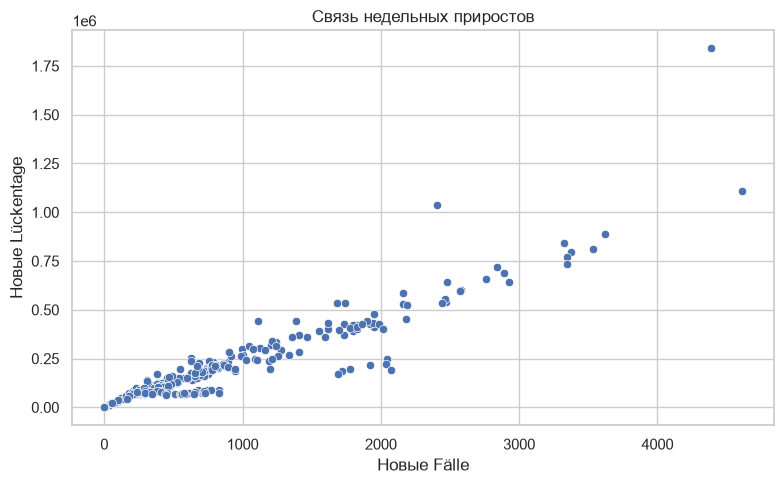

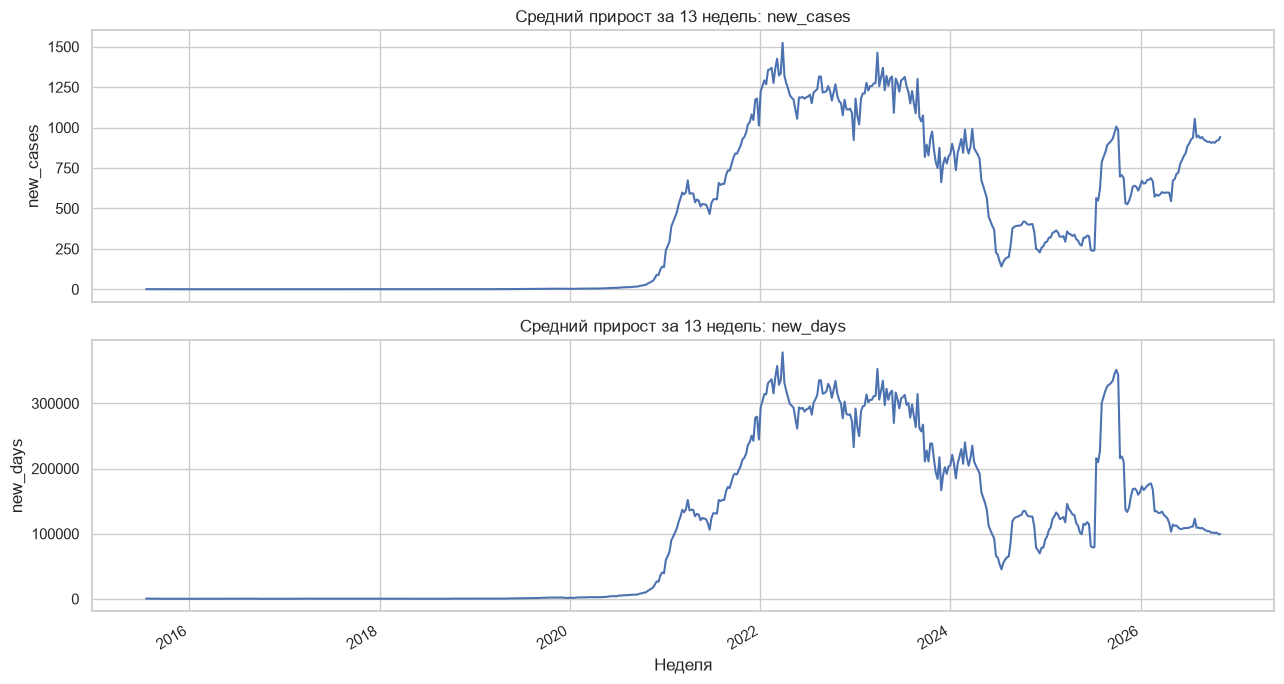

,new_cases,new_days,missing_week
week,,,
2025-07-14,4388.0,1839963.0,False
2022-05-30,4612.0,1110357.0,False
2025-08-04,2403.0,1037385.0,False
2023-01-23,3623.0,890483.0,False
2022-08-29,3327.0,842732.0,False
2023-06-05,3531.0,811123.0,False
2022-01-03,3374.0,797143.0,False
2023-01-02,3343.0,768434.0,False
2023-06-26,3345.0,734632.0,False


In [5]:
complete = weekly.loc[weekly["complete_calendar_week"]].copy()
complete["days_per_case"] = complete["new_days"].div(complete["new_cases"].replace(0, np.nan))
diagnostics = []
for metric in ["new_cases", "new_days"]:
    series = complete[metric]
    q1, q3 = series.quantile([.25, .75]) if len(series) else (np.nan, np.nan)
    threshold = q3 + 1.5 * (q3 - q1)
    total = series.sum()
    diagnostics.append({
        "metric": metric, "weeks": len(series),
        "missing_weeks": int(complete["missing_week"].sum()),
        "zero_share": series.eq(0).mean(), "mean": series.mean(),
        "median": series.median(), "std": series.std(),
        "cv": series.std() / series.mean() if series.mean() else np.nan,
        "top_week_share": series.max() / total if total else np.nan,
        "iqr_upper_outliers": int(series.gt(threshold).sum()),
        "lag_1": series.autocorr(1) if len(series) >= 10 and series.nunique() > 1 else np.nan,
        "lag_52": series.autocorr(52) if len(series) >= 104 and series.nunique() > 1 else np.nan,
    })
display(pd.DataFrame(diagnostics))
display(complete[["new_cases", "new_days", "days_per_case"]].describe())
display(complete[["new_cases", "new_days"]].corr())
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=complete, x="new_cases", y="new_days", ax=ax)
ax.set(title="Связь недельных приростов", xlabel="Новые Fälle", ylabel="Новые Lückentage")
show(fig)
rolling = complete[["new_cases", "new_days"]].rolling(13, min_periods=4).mean()
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, metric in zip(axes, ["new_cases", "new_days"]):
    sns.lineplot(data=rolling, x=rolling.index, y=metric, ax=ax)
    ax.set(title=f"Средний прирост за 13 недель: {metric}", ylabel=metric, xlabel="Неделя")
fig.autofmt_xdate()
show(fig)
display(complete.nlargest(10, "new_days")[["new_cases", "new_days", "missing_week"]])


## 5. Сравнение когорт и пригодность отдельных рядов

Для каждой комбинации анкерного года и Sachverhalt строится отдельный ряд.
Пересекающие несколько лет случаи могут входить в несколько когорт, поэтому
суммировать их размеры между годами нельзя.

Практические пороги ниже служат предварительным фильтром: 52 недели обучения
и минимум один горизонт проверки. Для проверки годовой сезонности желательно
иметь несколько полных годовых циклов. Наличие нужного числа недель не доказывает
качество будущей модели. График относительного возраста выравнивает когорты
по окончанию анкерного года.


,ankerjahr,sachverhalt,cases,days,calendar_weeks,weeks_with_records,missing_week_share,first_week,last_record_week,enough_calendar_history,coverage_confirmed,usable_weeks_under_assumption
0,2024,000,13314,2085851.0,558,324,0.419355,2016-02-29,2026-11-09,True,False,324
1,2024,004,141594,37670147.0,589,312,0.470289,2015-07-27,2026-02-02,True,False,312
2,2024,005,848,299847.0,337,153,0.545994,2020-05-25,2026-11-09,True,False,153
3,2024,01a,15280,1088119.0,593,183,0.691400,2015-06-29,2026-11-09,True,False,183
4,2024,01b,55109,13690984.0,593,349,0.411467,2015-06-29,2026-11-09,True,False,349
5,2024,01c,12339,246691.0,403,112,0.722084,2019-02-18,2026-10-12,True,False,112
6,2024,02b,6390,1417946.0,424,141,0.667453,2018-09-24,2023-07-10,True,False,141
7,2024,03b,3396,722874.0,520,136,0.738462,2016-11-21,2023-07-10,True,False,136
8,2024,04a,2267,725840.0,201,105,0.477612,2023-01-02,2026-03-30,True,False,105
9,2024,04b,237,70754.0,176,63,0.642045,2023-06-26,2026-03-30,True,False,63


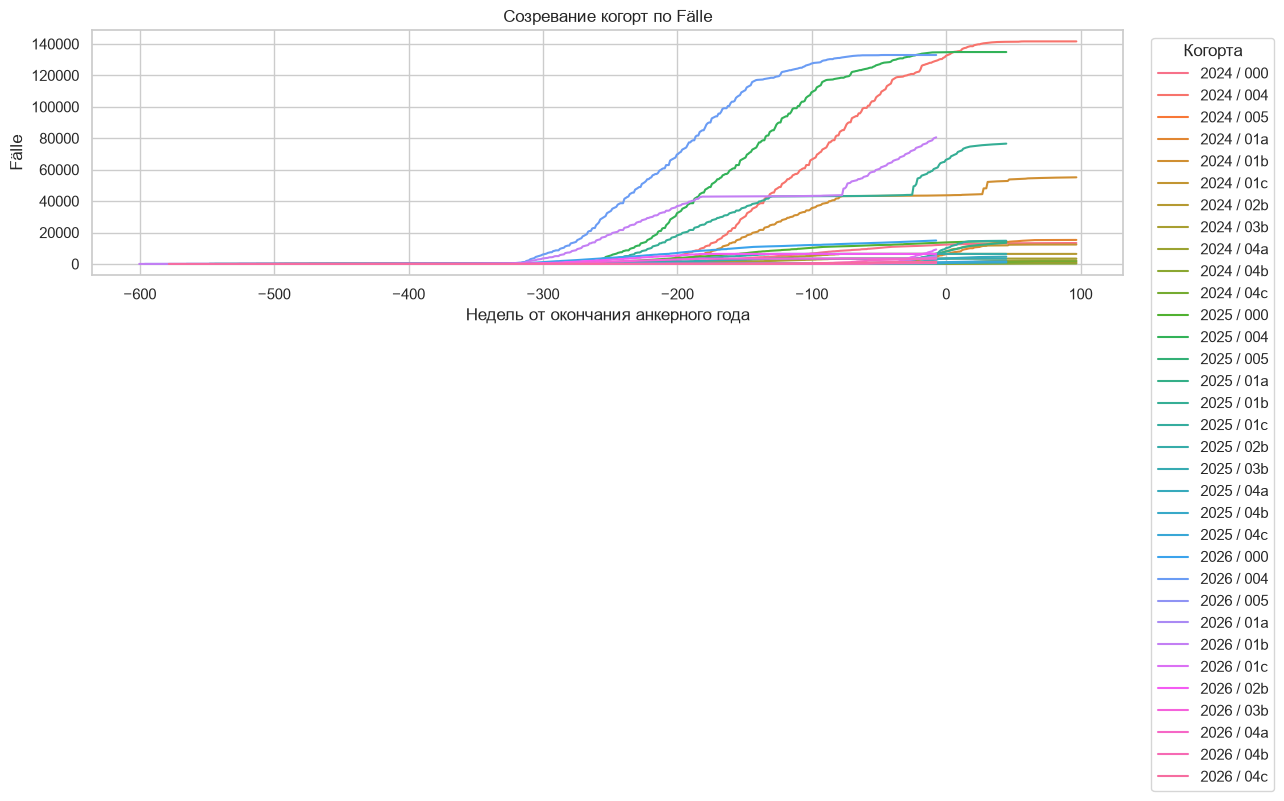

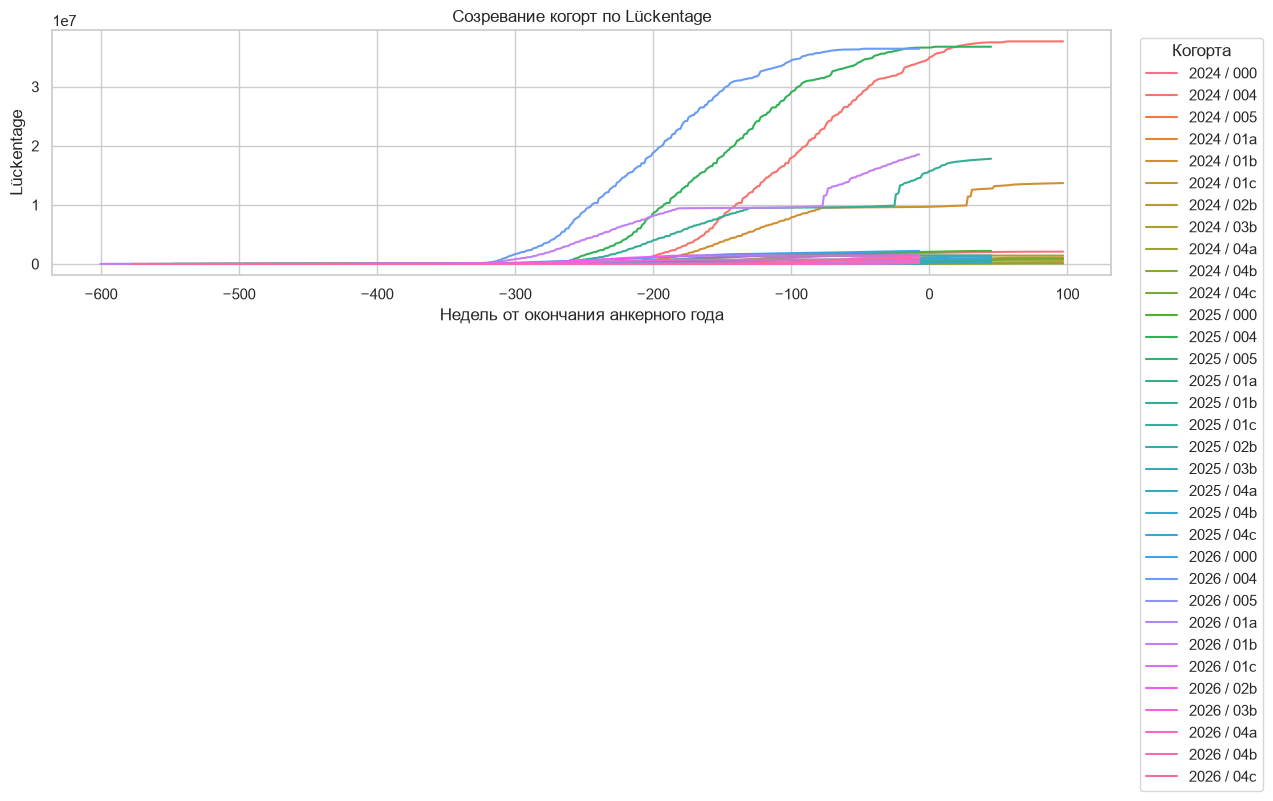

In [6]:
# Ограничение числа лет можно изменить для большой базы.
comparison_years = list(range(max(years) - 2, max(years) + 1))
categories = sorted(valid["sachverhalt"].dropna().unique())
summaries, maturity = [], []
for year in comparison_years:
    for category in categories:
        source = load_anchor_cohort_weekly_data(category, year)
        if source.empty:
            continue
        frame = regularize(source, observation_end)
        finished = frame.loc[frame["complete_calendar_week"]]
        usable = len(finished) if CONFIRMED_COMPLETE_EXTRACT else int((~finished["missing_week"]).sum())
        summaries.append({
            "ankerjahr": year, "sachverhalt": category,
            "cases": int(source["FAELLE"].sum()), "days": source["TAGEN"].sum(),
            "calendar_weeks": len(finished), "weeks_with_records": int((~finished["missing_week"]).sum()),
            "missing_week_share": finished["missing_week"].mean(),
            "first_week": frame.index.min(), "last_record_week": source["IPL_dt"].max(),
            "enough_calendar_history": len(finished) >= MIN_TRAIN_WEEKS + HORIZON_WEEKS,
            "coverage_confirmed": CONFIRMED_COMPLETE_EXTRACT,
            "usable_weeks_under_assumption": usable,
        })
        if selected_category in ("all", category):
            path = frame[["cumulative_cases", "cumulative_days"]].copy()
            path["weeks_from_anchor_year_end"] = (
                (path.index - pd.Timestamp(year, 12, 31)).days / 7
            )
            path["cohort"] = f"{year} / {category}"
            maturity.append(path.reset_index())
summary = pd.DataFrame(summaries)
display(summary)
if maturity:
    aligned = pd.concat(maturity, ignore_index=True)
    for metric, title in [("cumulative_cases", "Fälle"), ("cumulative_days", "Lückentage")]:
        fig, ax = plt.subplots(figsize=(13, 6))
        sns.lineplot(data=aligned, x="weeks_from_anchor_year_end", y=metric,
                     hue="cohort", estimator=None, ax=ax)
        ax.set(title=f"Созревание когорт по {title}",
               xlabel="Недель от окончания анкерного года", ylabel=title)
        ax.legend(title="Когорта", bbox_to_anchor=(1.02, 1), loc="upper left")
        show(fig)


## 6. Автокорреляция и стационарность приростов

Исследуем регулярные недельные приросты, исключая незавершённую неделю.
При неподтверждённой полноте используем самый длинный непрерывный отрезок недель
с записями: удалять отдельные пропуски и склеивать оставшиеся недели нельзя.
Полный ряд с нулями остаётся сценарной версией предыдущих графиков.

ACF/PACF показывают зависимость по неделям. Полосы 95% точечные, множество лагов
увеличивает риск случайных пиков. ACF не доказывает предсказуемость.
ADF проверяет гипотезу единичного корня, KPSS — стационарности вокруг константы.
Оба теста чувствительны к длине ряда, выбросам и изменениям режима.


,Основа диагностики
Завершённых календарных недель,593
Недель диагностического отрезка,56
Начало,2025-10-13 00:00:00
Конец,2026-11-02 00:00:00
Полнота подтверждена,False


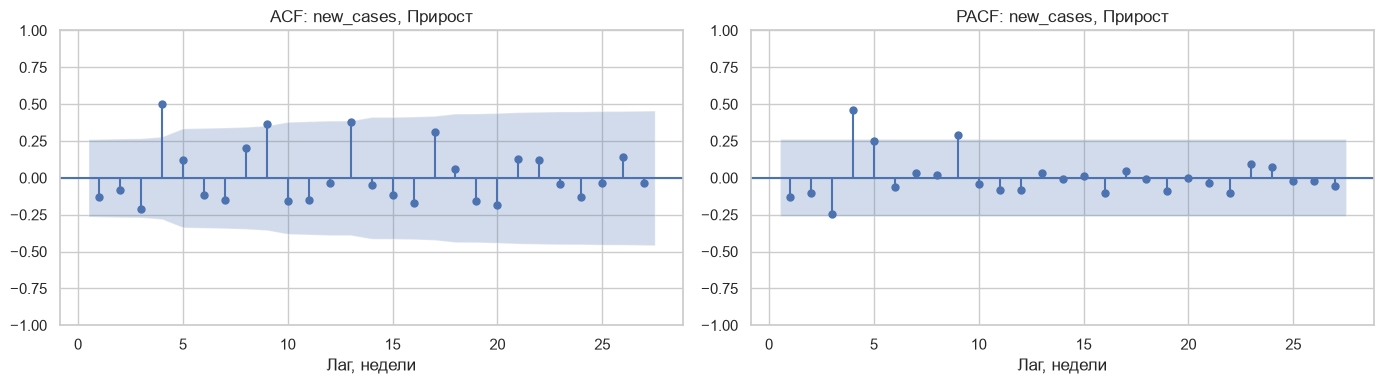

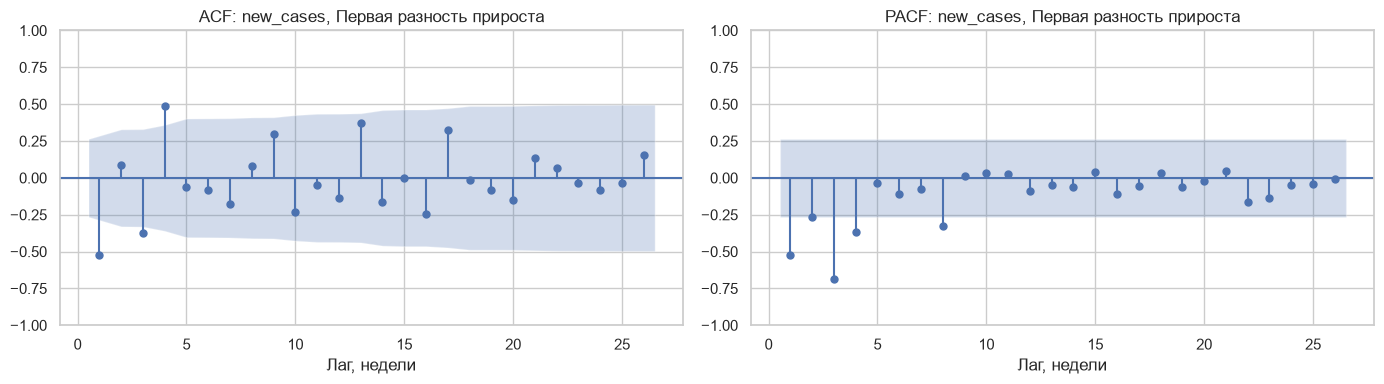

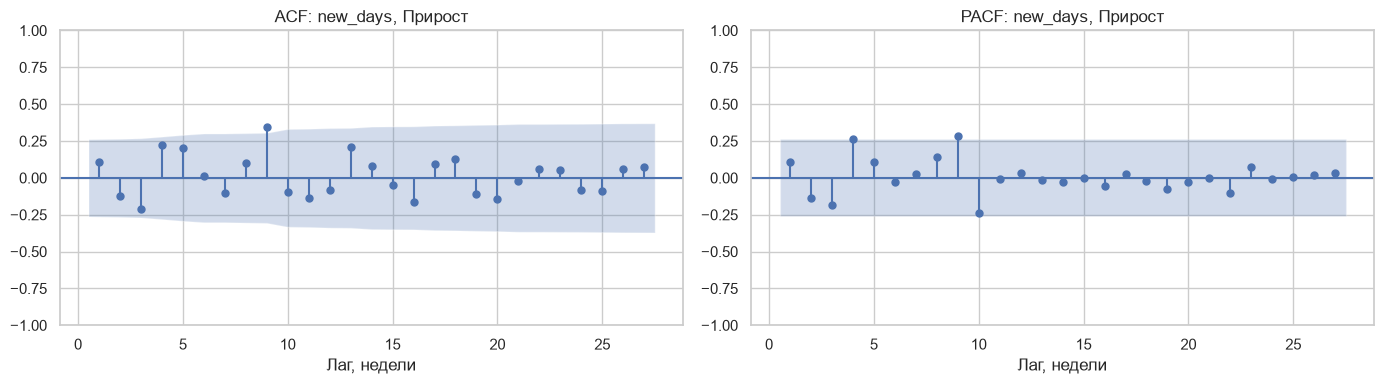

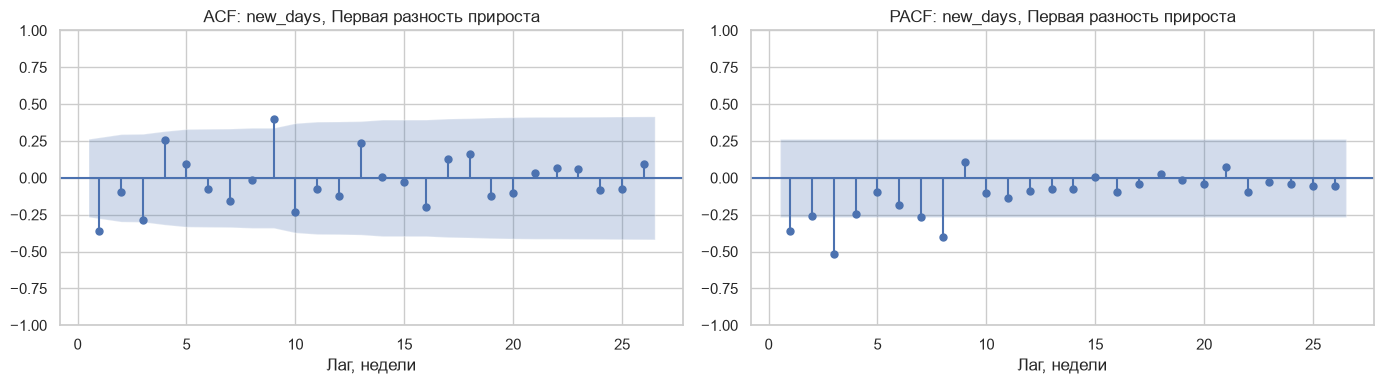

,metric,transform,n,adf_p,kpss_p,status,warnings
0,new_cases,Прирост,56,4.296293e-01,0.014259,Тесты указывают на нестационарность,adfuller currently returns a plain tuple whose...
1,new_cases,Первая разность прироста,55,5.464179e-15,0.100000,Тесты согласуются со стационарностью,adfuller currently returns a plain tuple whose...
2,new_days,Прирост,56,1.243573e-04,0.043389,"Неоднозначно: проверить тренд, длину и сдвиги",adfuller currently returns a plain tuple whose...
3,new_days,Первая разность прироста,55,4.193580e-13,0.100000,Тесты согласуются со стационарностью,adfuller currently returns a plain tuple whose...


,metric,lag_weeks,acf,pairs
0,new_cases,1,-0.131710,55
1,new_cases,4,0.544132,52
2,new_cases,13,0.494900,43
3,new_cases,26,0.352475,30
4,new_cases,52,NaN,4
5,new_days,1,0.108578,55
6,new_days,4,0.228864,52
7,new_days,13,0.380402,43
8,new_days,26,0.206154,30
9,new_days,52,NaN,4


In [7]:
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL

def analysis_segment(frame):
    finished = frame.loc[frame["complete_calendar_week"]]
    if CONFIRMED_COMPLETE_EXTRACT or finished.empty:
        return finished.copy()
    available = ~finished["missing_week"]
    groups = available.ne(available.shift()).cumsum()
    segments = [group for _, group in finished.loc[available].groupby(groups[available])]
    return max(segments, key=len).copy() if segments else finished.iloc[:0].copy()

analysis = analysis_segment(weekly)
display(pd.Series({
    "Завершённых календарных недель": len(complete),
    "Недель диагностического отрезка": len(analysis),
    "Начало": analysis.index.min(),
    "Конец": analysis.index.max(),
    "Полнота подтверждена": CONFIRMED_COMPLETE_EXTRACT,
}).to_frame("Основа диагностики"))

def stationarity_tests(series):
    series = series.astype(float)
    result = {"n": len(series), "adf_p": np.nan, "kpss_p": np.nan, "status": ""}
    if len(series) < 24 or series.nunique() < 2:
        result["status"] = "Недостаточно наблюдений / постоянный ряд"
        return result
    messages = []
    for name, test in [
        ("adf", lambda: adfuller(series, regression="c", autolag="AIC")[1]),
        ("kpss", lambda: kpss(series, regression="c", nlags="auto")[1]),
    ]:
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                result[f"{name}_p"] = test()
            messages.extend(str(w.message) for w in caught)
        except (ValueError, np.linalg.LinAlgError) as exc:
            messages.append(f"{name}: {exc}")
    adf_p, kpss_p = result["adf_p"], result["kpss_p"]
    if np.isfinite(adf_p) and np.isfinite(kpss_p):
        if adf_p < .05 and kpss_p >= .05:
            result["status"] = "Тесты согласуются со стационарностью"
        elif adf_p >= .05 and kpss_p < .05:
            result["status"] = "Тесты указывают на нестационарность"
        else:
            result["status"] = "Неоднозначно: проверить тренд, длину и сдвиги"
    result["warnings"] = " | ".join(messages)
    return result

test_rows, correlation_rows = [], []
for metric in ["new_cases", "new_days"]:
    for transform, series in [
        ("Прирост", analysis[metric]),
        ("Первая разность прироста", analysis[metric].diff().dropna()),
    ]:
        test_rows.append({"metric": metric, "transform": transform, **stationarity_tests(series)})
        if len(series) < 8 or series.nunique() < 2:
            continue
        lags = min(52, len(series) // 2 - 1)
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        plot_acf(series, lags=lags, zero=False, alpha=.05, ax=axes[0])
        plot_pacf(series, lags=lags, zero=False, alpha=.05, method="ywm", ax=axes[1])
        axes[0].set_title(f"ACF: {metric}, {transform}")
        axes[1].set_title(f"PACF: {metric}, {transform}")
        for ax in axes:
            ax.set_xlabel("Лаг, недели")
        show(fig)
    for lag in [1, 4, 13, 26, 52]:
        series = analysis[metric]
        correlation_rows.append({
            "metric": metric, "lag_weeks": lag,
            "acf": series.autocorr(lag) if len(series) >= max(24, 2 * lag) and series.nunique() > 1 else np.nan,
            "pairs": max(0, len(series) - lag),
        })
stationarity = pd.DataFrame(test_rows)
display(stationarity)
display(pd.DataFrame(correlation_rows))


## 7. Календарная сезонность и созревание

Профили и тепловая карта показывают различия по календарным годам. Общий профиль
может смешивать сезонность, созревание когорты и изменения процесса загрузки.
STL с периодом 52 — приближение годового цикла для недельной сетки.
Выполняем его при наличии хотя бы 156 последовательных недель; это практический
минимум для исследования, а не доказательство устойчивой сезонности.


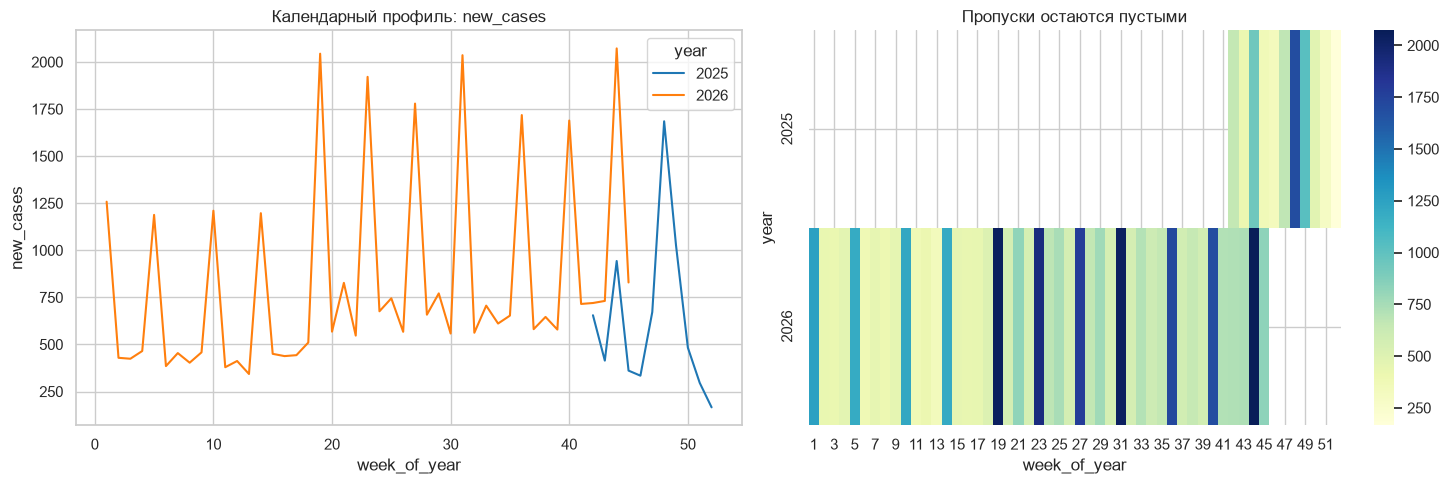

new_cases: STL пропущен — нужно минимум 156 последовательных недель и непостоянный ряд.


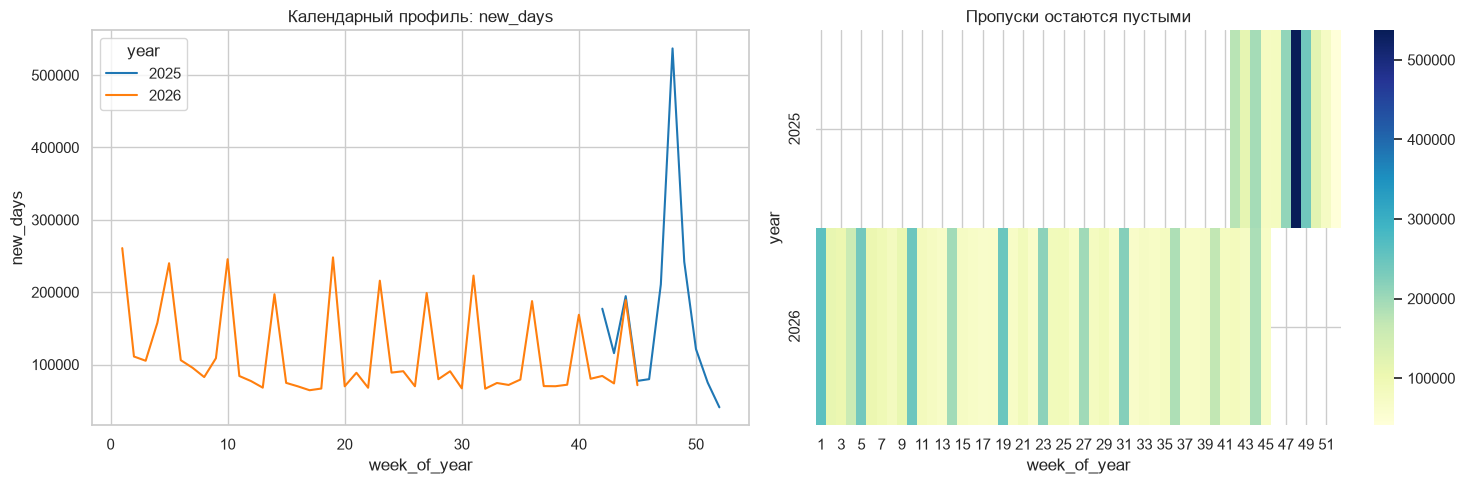

new_days: STL пропущен — нужно минимум 156 последовательных недель и непостоянный ряд.


In [8]:
for metric in ["new_cases", "new_days"]:
    calendar = analysis[[metric]].copy()
    calendar["year"] = calendar.index.isocalendar().year.astype(int)
    calendar["week_of_year"] = calendar.index.isocalendar().week.astype(int)
    if not calendar.empty:
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        sns.lineplot(data=calendar, x="week_of_year", y=metric, hue="year",
                     palette="tab10", estimator=None, ax=axes[0])
        axes[0].set_title(f"Календарный профиль: {metric}")
        matrix = calendar.pivot_table(index="year", columns="week_of_year", values=metric)
        sns.heatmap(matrix, cmap="YlGnBu", ax=axes[1])
        axes[1].set_title("Пропуски остаются пустыми")
        show(fig)
    if len(analysis) >= 156 and analysis[metric].nunique() > 1:
        decomposition = STL(analysis[metric].astype(float), period=52, robust=True).fit()
        fig = decomposition.plot()
        fig.set_size_inches(13, 9)
        fig.suptitle(f"STL, период 52: {metric}", y=1.01)
        show(fig)
    else:
        print(f"{metric}: STL пропущен — нужно минимум 156 последовательных недель и непостоянный ряд.")


## 8. Изменение среднего, разброса и частоты нулей

Сравниваем последовательные блоки по 13 недель. Последний короткий блок показан
с фактическим размером. Изменение среднего не является автоматическим доказательством
смены режима: оно может отражать созревание когорты.


,metric,start,end,weeks,mean,std,zero_share,max,days_per_case
0,new_cases,2025-10-13,2026-01-05,13,671.000000,441.495376,0.0,1685.0,257.162329
1,new_cases,2026-01-12,2026-04-06,13,597.538462,344.313717,0.0,1210.0,211.387616
2,new_cases,2026-04-13,2026-07-06,13,901.769231,590.337919,0.0,2044.0,121.060394
3,new_cases,2026-07-13,2026-10-05,13,909.615385,525.555030,0.0,2036.0,111.735814
4,new_cases,2026-10-12,2026-11-02,4,1088.000000,657.827232,0.0,2072.0,96.143153
5,new_days,2025-10-13,2026-01-05,13,172555.923077,129594.510159,0.0,536936.0,257.162329
6,new_days,2026-01-12,2026-04-06,13,126312.230769,62876.019054,0.0,245554.0,211.387616
7,new_days,2026-04-13,2026-07-06,13,109168.538462,65124.676434,0.0,248076.0,121.060394
8,new_days,2026-07-13,2026-10-05,13,101636.615385,53712.725105,0.0,222900.0,111.735814
9,new_days,2026-10-12,2026-11-02,4,104603.750000,56512.442408,0.0,188966.0,96.143153


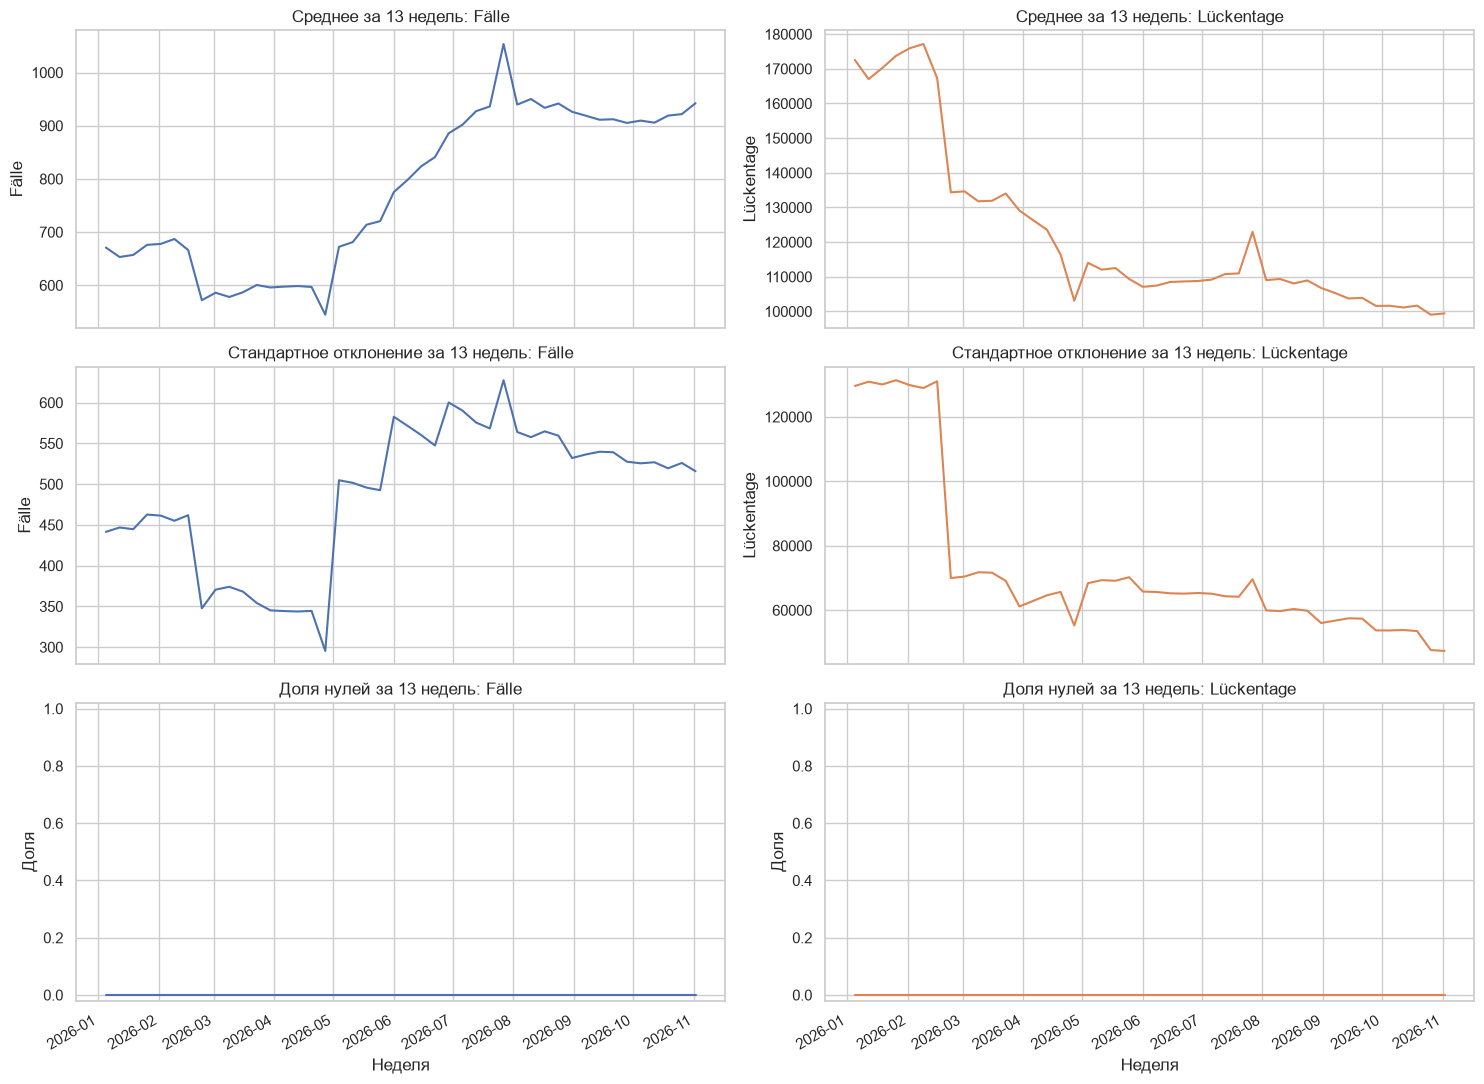

In [9]:
stability_rows = []
for metric in ["new_cases", "new_days"]:
    for _, block in analysis.groupby(np.arange(len(analysis)) // 13):
        series = block[metric]
        stability_rows.append({
            "metric": metric, "start": block.index.min(), "end": block.index.max(),
            "weeks": len(block), "mean": series.mean(), "std": series.std(),
            "zero_share": series.eq(0).mean(), "max": series.max(),
            "days_per_case": block["new_days"].sum() / block["new_cases"].sum()
                if block["new_cases"].sum() else np.nan,
        })
stability = pd.DataFrame(stability_rows)
display(stability)
if not analysis.empty:
    fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
    for column, (metric, label) in enumerate([
        ("new_cases", "Fälle"), ("new_days", "Lückentage"),
    ]):
        series = analysis[metric]
        rolling = series.rolling(13, min_periods=13)
        statistics = [
            (rolling.mean(), "Среднее за 13 недель", label),
            (rolling.std(), "Стандартное отклонение за 13 недель", label),
            (series.eq(0).rolling(13, min_periods=13).mean(), "Доля нулей за 13 недель", "Доля"),
        ]
        for row, (values, title, unit) in enumerate(statistics):
            ax = axes[row, column]
            ax.plot(values.index, values, color=f"C{column}")
            ax.set(title=f"{title}: {label}", ylabel=unit)
            if row == 2:
                ax.set_ylim(-0.02, 1.02)
                ax.set_xlabel("Неделя")
    fig.autofmt_xdate()
    show(fig)


## 9. Заключение по каждой когорте

Сводка — основание для выбора экспериментов, а не автоматическое одобрение модели.
Тесты приводятся для приростов обеих величин. Кандидаты требуют проверки на
одинаковых горизонтах относительно простых baseline. Сезонные модели требуют
подтверждения повторяемости рисунка. Неподтверждённое покрытие блокирует окончательный
вывод о качестве. Графики выше относятся к выбранной когорте; сводка охватывает
все комбинации из раздела 5.


In [10]:
assessment_rows = []
for year in comparison_years:
    for category in categories:
        source = load_anchor_cohort_weekly_data(category, year)
        if source.empty:
            continue
        frame = regularize(source, observation_end)
        segment = analysis_segment(frame)
        finished = frame.loc[frame["complete_calendar_week"]]
        for metric in ["new_cases", "new_days"]:
            series = segment[metric]
            tests = stationarity_tests(series)
            q1, q3 = series.quantile([.25, .75]) if len(series) else (np.nan, np.nan)
            outliers = int(series.gt(q3 + 1.5 * (q3 - q1)).sum())
            candidates = "Нулевой прирост; последнее значение; среднее/медиана окна"
            if len(series) >= 52 and series.nunique() > 1:
                candidates += "; проверить затухающий ETS и ARIMA"
            blockers = []
            if not CONFIRMED_COMPLETE_EXTRACT:
                blockers.append("Подтвердить полноту и нулевые недели")
            if len(series) < MIN_TRAIN_WEEKS + HORIZON_WEEKS:
                blockers.append("Мало последовательных недель для выбранного горизонта")
            if outliers:
                blockers.append("Объяснить недельные скачки")
            assessment_rows.append({
                "ankerjahr": year, "sachverhalt": category, "metric": metric,
                "calendar_weeks": len(finished), "diagnostic_weeks": len(series),
                "missing_week_share": finished["missing_week"].mean(),
                "zero_share_in_segment": series.eq(0).mean(),
                "iqr_upper_outliers": outliers,
                "acf_1": series.autocorr(1) if len(series) >= 24 and series.nunique() > 1 else np.nan,
                "acf_52": series.autocorr(52) if len(series) >= 104 and series.nunique() > 1 else np.nan,
                "adf_p": tests["adf_p"], "kpss_p": tests["kpss_p"],
                "stationarity": tests["status"], "test_warnings": tests.get("warnings", ""),
                "annual_cycles": round(len(series) / 52, 1),
                "seasonality_status": "Проверить календарные профили / STL" if len(series) >= 156 else "Мало циклов для устойчивого вывода",
                "candidate_models": candidates,
                "limitations": "; ".join(blockers) or "Нужна проверка прогноза на исторических срезах",
            })
assessment = pd.DataFrame(assessment_rows)
display(assessment)


,ankerjahr,sachverhalt,metric,calendar_weeks,diagnostic_weeks,missing_week_share,zero_share_in_segment,iqr_upper_outliers,acf_1,acf_52,adf_p,kpss_p,stationarity,test_warnings,annual_cycles,seasonality_status,candidate_models,limitations
0,2024,000,new_cases,558,28,0.419355,0.0,0,0.298354,NaN,7.660508e-01,0.044096,Тесты указывают на нестационарность,adfuller currently returns a plain tuple whose...,0.5,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
1,2024,000,new_days,558,28,0.419355,0.0,0,0.104419,NaN,5.528982e-02,0.100000,"Неоднозначно: проверить тренд, длину и сдвиги",adfuller currently returns a plain tuple whose...,0.5,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
2,2024,004,new_cases,589,22,0.470289,0.0,2,NaN,NaN,NaN,NaN,Недостаточно наблюдений / постоянный ряд,,0.4,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
3,2024,004,new_days,589,22,0.470289,0.0,2,NaN,NaN,NaN,NaN,Недостаточно наблюдений / постоянный ряд,,0.4,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
4,2024,005,new_cases,337,25,0.545994,0.0,1,0.395909,NaN,1.508350e-14,0.024054,"Неоднозначно: проверить тренд, длину и сдвиги",adfuller currently returns a plain tuple whose...,0.5,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,2026,04a,new_days,201,56,0.393035,0.0,7,0.383380,NaN,9.350332e-06,0.012011,"Неоднозначно: проверить тренд, длину и сдвиги",adfuller currently returns a plain tuple whose...,1.1,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
62,2026,04b,new_cases,170,51,0.494118,0.0,5,0.404287,NaN,2.792527e-08,0.033246,"Неоднозначно: проверить тренд, длину и сдвиги",adfuller currently returns a plain tuple whose...,1.0,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
63,2026,04b,new_days,170,51,0.494118,0.0,4,0.363953,NaN,2.058900e-11,0.010000,"Неоднозначно: проверить тренд, длину и сдвиги",adfuller currently returns a plain tuple whose...,1.0,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...
64,2026,04c,new_cases,571,26,0.744308,0.0,1,0.044335,NaN,7.513049e-01,0.023302,Тесты указывают на нестационарность,adfuller currently returns a plain tuple whose...,0.5,Мало циклов для устойчивого вывода,Нулевой прирост; последнее значение; среднее/м...,Подтвердить полноту и нулевые недели; Мало пос...


## 10. Проверяемость будущего прогноза

Показываем возможные границы rolling-origin проверки на равномерной сетке.
Это календарный план, модель здесь не обучается. Последняя незавершённая неделя
исключена. Неподтверждённые нули делают оценку качества условной.

Последние значения дней из IPL-снимков могли стать известны позже даты отсечения.
Для честного backtesting нужно восстановить состояние каждого случая по IPL,
доступному на тот момент, и проверить, что выгрузка содержит нужную историю снимков.
Ось целевого ряда при этом остаётся erstes Ladedatum.


In [11]:
folds = []
for origin_index in range(MIN_TRAIN_WEEKS - 1, len(complete) - HORIZON_WEEKS, HORIZON_WEEKS):
    train = complete.iloc[:origin_index + 1]
    test = complete.iloc[origin_index + 1:origin_index + 1 + HORIZON_WEEKS]
    folds.append({
        "train_start": train.index.min(), "train_end": train.index.max(),
        "test_start": test.index.min(), "test_end": test.index.max(),
        "train_weeks": len(train), "test_weeks": len(test),
        "test_missing_weeks": int(test["missing_week"].sum()),
    })
display(pd.DataFrame(folds))
recommendations = [
    ("Даты и числовые значения", "Требует проверки" if quality["Строк"].sum() else "Проверки пройдены"),
    ("Покрытие недель", "Подтверждено пользователем" if CONFIRMED_COMPLETE_EXTRACT else "Нужно подтвердить полноту выгрузки"),
    ("Календарная глубина", "Достаточно для пробной проверки" if folds else "Недостаточно при выбранных train/horizon"),
    ("IPL и утечка будущих данных", "Проверить возможность восстановления исторических срезов"),
    ("Прогнозная точность", "Оценивается отдельно на backtesting"),
]
display(pd.DataFrame(recommendations, columns=["Область", "Вывод"]))
database_hash_after = hashlib.sha256(database.read_bytes()).hexdigest()
print("Файл базы не изменился за время исследования:", database_hash_after == database_hash_before)


,train_start,train_end,test_start,test_end,train_weeks,test_weeks,test_missing_weeks
0,2015-06-29,2016-06-20,2016-06-27,2016-09-19,52,13,10
1,2015-06-29,2016-09-19,2016-09-26,2016-12-19,65,13,12
2,2015-06-29,2016-12-19,2016-12-26,2017-03-20,78,13,8
3,2015-06-29,2017-03-20,2017-03-27,2017-06-19,91,13,10
4,2015-06-29,2017-06-19,2017-06-26,2017-09-18,104,13,11
5,2015-06-29,2017-09-18,2017-09-25,2017-12-18,117,13,10
6,2015-06-29,2017-12-18,2017-12-25,2018-03-19,130,13,11
7,2015-06-29,2018-03-19,2018-03-26,2018-06-18,143,13,13
8,2015-06-29,2018-06-18,2018-06-25,2018-09-17,156,13,10
9,2015-06-29,2018-09-17,2018-09-24,2018-12-17,169,13,9


,Область,Вывод
0,Даты и числовые значения,Требует проверки
1,Покрытие недель,Нужно подтвердить полноту выгрузки
2,Календарная глубина,Достаточно для пробной проверки
3,IPL и утечка будущих данных,Проверить возможность восстановления историчес...
4,Прогнозная точность,Оценивается отдельно на backtesting


Файл базы не изменился за время исследования: True


## Вывод исследователя

После просмотра результатов заполните:

- Какие Ankerjahr × Sachverhalt имеют достаточно наблюдений?
- Какие недели без записей подтверждены как нулевые приросты?
- Чем объясняются крупнейшие недельные скачки: поступление случаев или пакетная загрузка?
- Устойчиво ли число Lückentage на случай и нужен ли отдельный прогноз этого отношения?
- Есть ли повторяющаяся сезонность и достаточно ли полных циклов для её проверки?
- Какой горизонт нужен бизнесу и сколько исторических окон его покрывают?
- Можно ли восстановить прошлые срезы без более поздних изменений дней?
- Какие ограничения нужно устранить до сравнения моделей?

Следующий шаг после согласования качества данных — сравнение простых baseline
и выбранных моделей на одинаковых исторических окнах.
